
Feature importance (normalised):
                                    XGBoost  Random Forest
Online boarding                     0.4217         0.1654
Type of Travel                      0.1338         0.1182
Inflight wifi service               0.1080         0.1380
Class                               0.0594         0.1108
Customer Type                       0.0534         0.0523
Inflight entertainment              0.0411         0.0584
Checkin service                     0.0268         0.0247
Cleanliness                         0.0205         0.0233
Leg room service                    0.0179         0.0340
On-board service                    0.0179         0.0273
Seat comfort                        0.0171         0.0395
Gate location                       0.0169         0.0142
Baggage handling                    0.0156         0.0250
Inflight service                    0.0121         0.0231
Ease of Online booking              0.0087         0.0352
Age                                 0

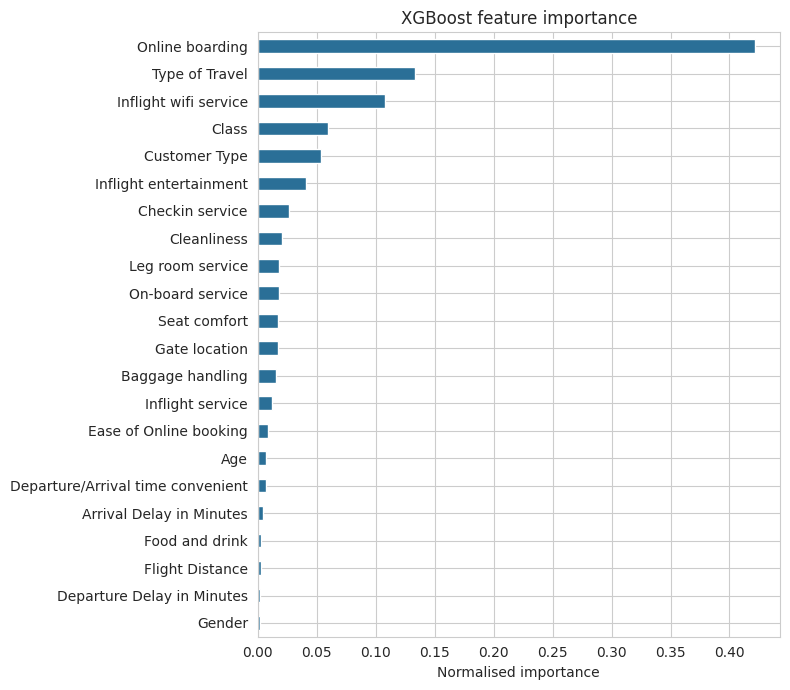

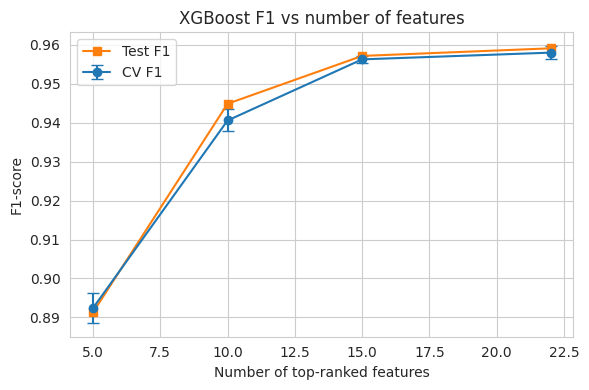

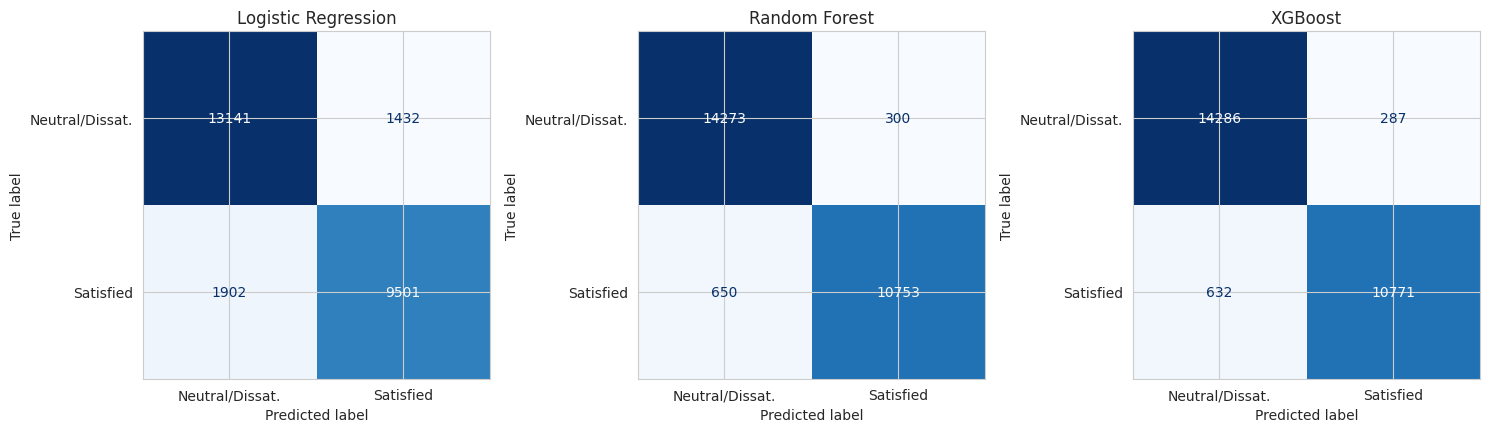

AUC Logistic Regression: 0.9256
AUC Random Forest: 0.9942
AUC XGBoost: 0.9954


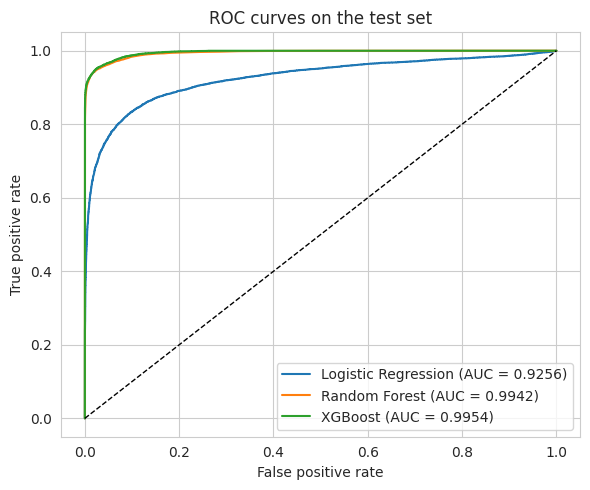

In [1]:

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (f1_score, accuracy_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, auc)
from xgboost import XGBClassifier

RS = 42
train = pd.read_csv("train.csv").drop_duplicates()
test = pd.read_csv("test.csv")
drop = ["Unnamed: 0", "id", "satisfaction"]
X_train, X_test = train.drop(columns=drop), test.drop(columns=drop)
y_train = (train["satisfaction"] == "satisfied").astype(int)
y_test = (test["satisfaction"] == "satisfied").astype(int)

CAT = ["Gender", "Customer Type", "Type of Travel", "Class"]
ALL = list(X_train.columns)  # 22 features
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)

def make_pipe(model, feats):
    cat = [f for f in feats if f in CAT]
    num = [f for f in feats if f not in CAT]
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("sc", StandardScaler())]), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat)])
    return Pipeline([("pre", pre), ("model", model)])

def xgb():
    return XGBClassifier(learning_rate=0.1, max_depth=7, n_estimators=200,
                         eval_metric="logloss", random_state=RS, n_jobs=-1)

models = {
    "Logistic Regression": LogisticRegression(C=0.1, penalty="l2", max_iter=1000, random_state=RS),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=None,
                                            min_samples_split=2, random_state=RS, n_jobs=-1),
    "XGBoost": xgb(),
}
fitted = {n: make_pipe(m, ALL).fit(X_train, y_train) for n, m in models.items()}

# ---------- 1) Feature importance (one-hot columns summed back to original feature)
def importance(pipe):
    names = pipe.named_steps["pre"].get_feature_names_out()
    imp = pipe.named_steps["model"].feature_importances_
    s = pd.Series(imp, index=names)
    orig = [next(f for f in ALL if n.split("__", 1)[1].startswith(f)) for n in s.index]
    s = s.groupby(orig).sum()
    return (s / s.sum()).sort_values(ascending=False)

imp_xgb, imp_rf = importance(fitted["XGBoost"]), importance(fitted["Random Forest"])
imp_table = pd.DataFrame({"XGBoost": imp_xgb, "Random Forest": imp_rf}).sort_values("XGBoost", ascending=False)
print("\nFeature importance (normalised):\n", imp_table.round(4))

# ---------- 2) Feature-selection experiment: top-k features by XGBoost importance
ranked = list(imp_xgb.index)
rows = []
for k in [5, 10, 15, 22]:
    feats = ranked[:k]
    cv_f1 = cross_val_score(make_pipe(xgb(), feats), X_train[feats], y_train,
                            cv=cv, scoring="f1", n_jobs=-1)
    p = make_pipe(xgb(), feats).fit(X_train[feats], y_train)
    rows.append({"Features": k, "CV F1": cv_f1.mean(), "CV std": cv_f1.std(),
                 "Test F1": f1_score(y_test, p.predict(X_test[feats])),
                 "Test Acc": accuracy_score(y_test, p.predict(X_test[feats]))})

# Extra variant: drop the weakest features found in Phase 4 (Gate location ~0.001
# correlation; Departure Delay redundant with Arrival Delay, r = 0.96)
weak = ["Gate location", "Departure Delay in Minutes"]
feats = [f for f in ALL if f not in weak]
cv_f1 = cross_val_score(make_pipe(xgb(), feats), X_train[feats], y_train, cv=cv, scoring="f1", n_jobs=-1)
p = make_pipe(xgb(), feats).fit(X_train[feats], y_train)
rows.append({"Features": "20 (weak removed)", "CV F1": cv_f1.mean(), "CV std": cv_f1.std(),
             "Test F1": f1_score(y_test, p.predict(X_test[feats])),
             "Test Acc": accuracy_score(y_test, p.predict(X_test[feats]))})
fs = pd.DataFrame(rows)
print("\nFeature-selection results (XGBoost):\n", fs.round(4))
print("\nTop-5 features:", ranked[:5])
print("Bottom-5 features:", ranked[-5:])

# ---------- 3) Visualizations
sns.set_style("whitegrid")

# Fig A – feature importance
fig, ax = plt.subplots(figsize=(8, 7))
imp_xgb.sort_values().plot.barh(ax=ax, color="#2a6f97")
ax.set_xlabel("Normalised importance"); ax.set_title("XGBoost feature importance")
plt.tight_layout(); plt.savefig("fig_feature_importance.png", dpi=200); plt.show()

# Fig B – F1 vs number of features
sub = fs[fs["Features"].apply(lambda v: isinstance(v, int))]
fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(sub["Features"], sub["CV F1"], yerr=sub["CV std"], marker="o", label="CV F1", capsize=4)
ax.plot(sub["Features"], sub["Test F1"], marker="s", label="Test F1")
ax.set_xlabel("Number of top-ranked features"); ax.set_ylabel("F1-score")
ax.set_title("XGBoost F1 vs number of features"); ax.legend()
plt.tight_layout(); plt.savefig("fig_f1_vs_features.png", dpi=200); plt.show()

# Fig C – confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (n, p) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p.predict(X_test)),
                           display_labels=["Neutral/Dissat.", "Satisfied"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(n)
plt.tight_layout(); plt.savefig("fig_confusion_matrices.png", dpi=200); plt.show()

# Fig D – ROC curves
fig, ax = plt.subplots(figsize=(6, 5))
for n, p in fitted.items():
    fpr, tpr, _ = roc_curve(y_test, p.predict_proba(X_test)[:, 1])
    ax.plot(fpr, tpr, label=f"{n} (AUC = {auc(fpr, tpr):.4f})")
    print(f"AUC {n}: {auc(fpr, tpr):.4f}")
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("ROC curves on the test set"); ax.legend()
plt.tight_layout(); plt.savefig("fig_roc_curves.png", dpi=200); plt.show()
